# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh | 5054251015 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [6]:
# Import library yang dibutuhkan.
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt



In [7]:
# Load dataset.
# Sesuaikan nama file dengan file dataset yang digunakan.

df = pd.read_csv('insurance.csv')

In [8]:
# Tampilkan beberapa baris pertama dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [10]:
# Periksa missing value.
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [11]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [12]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
df.select_dtypes(include='object').nunique()

sex       2
smoker    2
region    4
dtype: int64

## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [13]:
# Pisahkan fitur (X) dan target (y).
X = df.drop('charges', axis=1)
y = df['charges']

In [14]:
# Identifikasi kolom numerik dan kategorikal.
X_numeric = X.select_dtypes(include=['int64', 'float64']).columns
X_categorical = X.select_dtypes(include=['object']).columns


In [15]:
from sklearn.model_selection import train_test_split

# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


X_train_numeric = X_train[X_numeric]
X_train_categorical = X_train[X_categorical]

X_test_numeric = X_test[X_numeric]
X_test_categorical = X_test[X_categorical]
# Buat preprocessing untuk fitur numerik dan kategorikal.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), X_numeric),
        ('cat', OneHotEncoder(), X_categorical)
    ]
) 


# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [16]:
from sklearn.linear_model import LinearRegression

In [17]:
# Inisialisasi dan latih Linear Regression.

X_Train_transformed = preprocessor.fit_transform(X_train)
model = LinearRegression()
model.fit(X_Train_transformed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[3614.98,2036.23, 516.89,..., 88.91,-198.28,-350.21]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.031e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,8
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[34.92,32.9 ,30.63,..., 0. , 0. , 0. ]"


In [18]:
# Lakukan prediksi pada test set.
X_test_transformed = preprocessor.transform(X_test)
y_pred = model.predict(X_test_transformed)

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, accuracy_score
# Hitung metrik evaluasi.
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


# Tampilkan hasil evaluasi.
print(f'MSE: {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAE: {mae:.2f}')
print(f'R^2: {r2:.2f}')

MSE: 33596915.85
RMSE: 5796.28
MAE: 4181.19
R^2: 0.78


## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [19]:
# Buat fitur polynomial dan latih model.
from sklearn.preprocessing import PolynomialFeatures

poly_1 = PolynomialFeatures(degree=2, include_bias=False)
X_poly_1 = poly_1.fit_transform(X_Train_transformed)

poly_2 = PolynomialFeatures(degree=3, include_bias=False)
X_poly_2 = poly_2.fit_transform(X_Train_transformed)


poly_model_1 = LinearRegression()
poly_model_1.fit(X_poly_1, y_train)

poly_model_2 = LinearRegression()
poly_model_2.fit(X_poly_2, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](363,)","[ 914.77,1443.3 , 40.39,..., 0. , 0. , -8.14]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.035e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,363
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,100
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](363,)","[175.7 ,148.26,105.92,..., 0. , 0. , 0. ]"


In [20]:
# Lakukan prediksi pada test set.
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, accuracy_score
poly_test_transformed_1 = poly_1.transform(X_test_transformed)
poly_test_transformed_2 = poly_2.transform(X_test_transformed)
y_pred_poly_1 = poly_model_1.predict(poly_test_transformed_1)
y_pred_poly_2 = poly_model_2.predict(poly_test_transformed_2)



r2 = r2_score(y_test, y_pred_poly_1)
mse = mean_squared_error(y_test, y_pred_poly_1)
abse = mean_absolute_error(y_test, y_pred_poly_1)

# Tampilkan hasil evaluasi.
print(f'MSE: {mse:.2f}')
print(f'RMSE: {np.sqrt(mse):.2f}')
print(f'MAE: {abse:.2f}')   
print(f'R^2: {r2:.2f}')

MSE: 20712805.99
RMSE: 4551.13
MAE: 2729.50
R^2: 0.87


## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [21]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge


model = Ridge(alpha=1)
model.fit(X_Train_transformed, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to

In [22]:
# Lakukan prediksi pada test set.
y_pred_ridge = model.predict(X_test_transformed)

print(f'MSE: {mean_squared_error(y_test, y_pred_ridge):.2f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_ridge)):.2f}')
print(f'MAE: {mean_absolute_error(y_test, y_pred_ridge):.2f}')
print(f'R^2: {r2_score(y_test, y_pred_ridge):.2f}')


MSE: 33620268.92
RMSE: 5798.30
MAE: 4186.91
R^2: 0.78


## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [23]:
# Inisialisasi dan latih Lasso Regression.
from sklearn.linear_model import Lasso

model_lasso = Lasso(alpha=0.1)
model_lasso.fit(X_Train_transformed, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [24]:
# Lakukan prediksi pada test set.
y_pred_lasso = model_lasso.predict(X_test_transformed)

print(f'MSE: {mean_squared_error(y_test, y_pred_lasso):.2f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_lasso)):.2f}')
print(f'MAE: {mean_absolute_error(y_test, y_pred_lasso):.2f}')
print(f'R^2: {r2_score(y_test, y_pred_lasso):.2f}')

MSE: 33597196.12
RMSE: 5796.31
MAE: 4181.23
R^2: 0.78


## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [25]:
# Inisialisasi dan latih Decision Tree Regressor.
from sklearn.tree import DecisionTreeRegressor

model_dt = DecisionTreeRegressor(random_state=42, max_depth=4)
model_dt.fit(X_Train_transformed, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [26]:
# Lakukan prediksi pada test set.
y_pred_dt = model_dt.predict(X_test_transformed)

print(f'MSE: {mean_squared_error(y_test, y_pred_dt):.2f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_dt)):.2f}')
print(f'MAE: {mean_absolute_error(y_test, y_pred_dt):.2f}')
print(f'R^2: {r2_score(y_test, y_pred_dt):.2f}')



MSE: 21093484.00
RMSE: 4592.76
MAE: 2697.77
R^2: 0.86


## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [27]:
# Inisialisasi dan latih SVR.
from sklearn.svm import SVR

model_svr = SVR(kernel='rbf', C=10000, gamma=0.1, epsilon=.1)
model_svr.fit(X_Train_transformed, y_train)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.1
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [28]:
# Lakukan prediksi pada test set.
y_pred_svr = model_svr.predict(X_test_transformed)

print(f'MSE: {mean_squared_error(y_test, y_pred_svr):.2f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_svr)):.2f}')
print(f'MAE: {mean_absolute_error(y_test, y_pred_svr):.2f}')
print(f'R^2: {r2_score(y_test, y_pred_svr):.2f}')

MSE: 22706732.01
RMSE: 4765.16
MAE: 1813.53
R^2: 0.85


# 4. Evaluasi Model

In [29]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
result = []
for model_name, y_pred in zip(['Linear Regression', 'Polynomial Regression (Degree 2)', 'Polynomial Regression (Degree 3)', 'Ridge Regression', 'Lasso Regression', 'Decision Tree Regressor', 'SVR'], [y_pred, y_pred_poly_1, y_pred_poly_2, y_pred_ridge, y_pred_lasso, y_pred_dt, y_pred_svr]):
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    result.append({'Model': model_name, 'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R²': r2})

df_result = pd.DataFrame(result)
df_result

,Model,MSE,RMSE,MAE,R²
0,Linear Regression,3.359692e+07,5796.284659,4181.194474,0.783593
1,Polynomial Regression (Degree 2),2.071281e+07,4551.132385,2729.500134,0.866583
2,Polynomial Regression (Degree 3),2.349822e+07,4847.496055,2937.918593,0.848641
3,Ridge Regression,3.362027e+07,5798.298795,4186.913072,0.783443
4,Lasso Regression,3.359720e+07,5796.308836,4181.225381,0.783591
5,Decision Tree Regressor,2.109348e+07,4592.764310,2697.765431,0.864131
6,SVR,2.270673e+07,4765.158131,1813.533506,0.853740


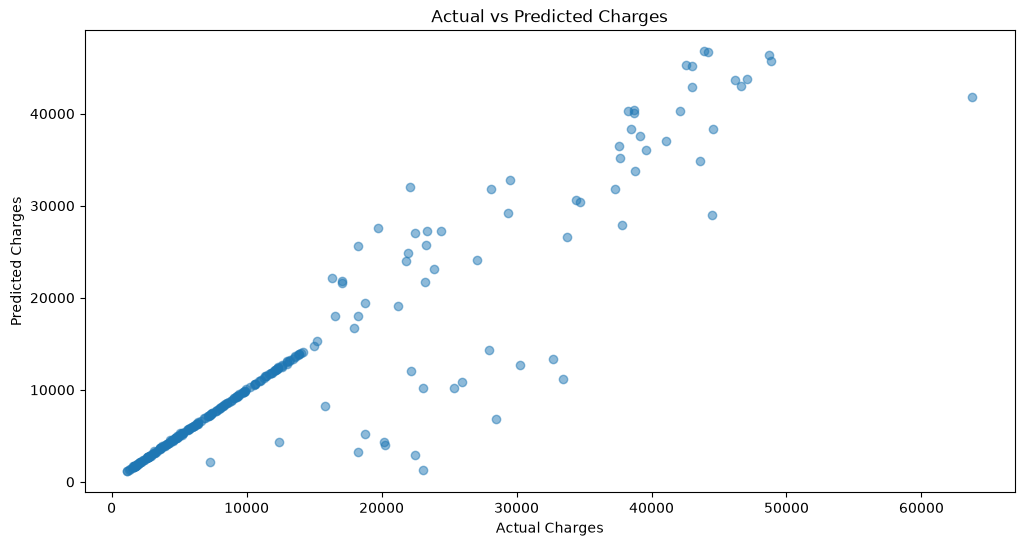

In [30]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

plt.figure(figsize=(12, 6))
plt.scatter(y_test, y_pred_svr, alpha=0.5)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')
plt.show()

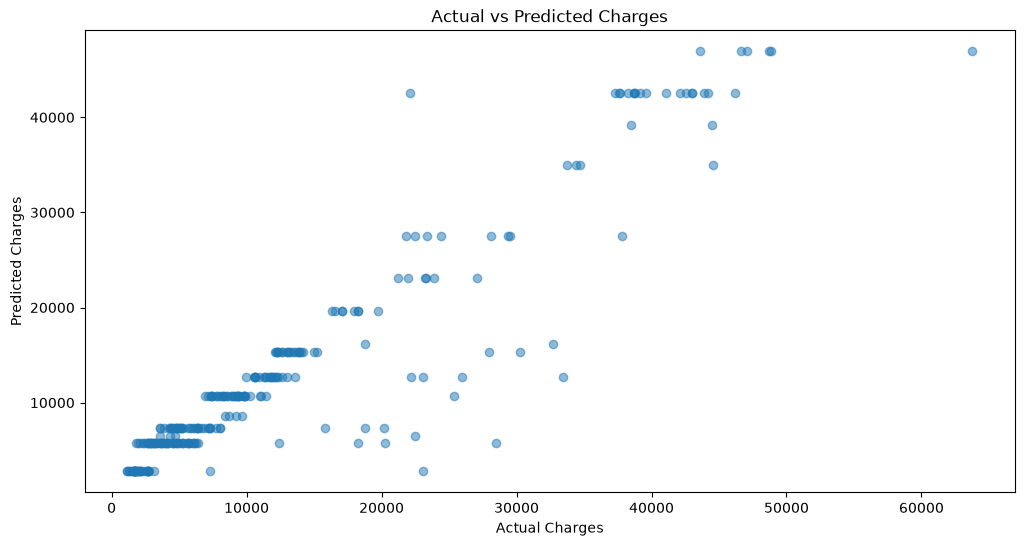

In [31]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

plt.figure(figsize=(12, 6))
plt.scatter(y_test, y_pred_dt, alpha=0.5)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.


# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.

### Kesimpulan
1. **Performa Terbaik Berdasarkan Metrik Evaluasi**:
   - **Polynomial Regression (Degree 2)** memperoleh skor ^2$ tertinggi yaitu **0.8666** serta error terendah pada metrik berbasis kuadrat (**RMSE: 4551.13**, **MSE: 2.071e+07**).
   - **SVR (RBF Kernel)** menghasilkan nilai **MAE terendah (1813.53)** dan ^2$ sebesar **0.8537**, menunjukkan akurasi deviasi absolut yang lebih baik terhadap sebagian besar titik data.
   - **Decision Tree Regressor (max_depth=4)** memiliki performa yang sangat kompetitif dengan ^2$ **0.8641** dan RMSE **4592.76**.
   - Model linear standar (**Linear Regression**, **Ridge**, dan **Lasso**) mencatatkan performa yang hampir identik dengan ^2 \approx$ **0.7836** dan RMSE $\approx$ **5796**, menunjukkan bahwa relasi murni linear memiliki batasan dalam menangkap pola non-linear pada data asuransi ini.

2. **Kompleksitas Derajat Polinomial**:
   - Meningkatkan derajat polinomial dari 2 ke 3 menyebabkan penurunan skor ^2$ (dari **0.8666** menjadi **0.8486**) dan kenaikan RMSE (dari **4551.13** menjadi **4847.50**), yang mengindikasikan adanya kecenderungan overfitting pada derajat yang lebih tinggi.

3. **Pengaruh Preprocessing Data**:
   - Penerapan  untuk fitur numerik dan  untuk fitur kategorikal melalui  menjaga konsistensi representasi fitur, khususnya penting bagi model berbasis jarak seperti SVR.

---

### Saran
1. **Optimasi Hyperparameter (Hyperparameter Tuning)**:
   - Melakukan pencarian parameter sistematis menggunakan  atau  (misalnya tuning parameter $, $\gamma$, dan $\epsilon$ pada SVR, regulasi $\alpha$ pada Ridge/Lasso, serta  dan  pada Decision Tree).

2. **Regularisasi pada Fitur Polinomial**:
   - Menggabungkan  dengan model terregularisasi ( atau ) untuk mengontrol multikolinearitas dan overfitting pada fitur berderajat tinggi.

3. **Eksplorasi Model Ensemble Lanjutan**:
   - Menguji algoritma ensemble tree-based seperti *Random Forest Regressor*, *Gradient Boosting*, atau *XGBoost/LightGBM*, yang umumnya efektif dalam menangani interaksi non-linear fitur tanpa memerlukan perluasan manual derajat polinomial.

4. **Validasi Silang (Cross-Validation)**:
   - Menerapkan hBcfold cross-validation untuk evaluasi performa model yang lebih representatif terhadap variasi split data train-test.
